# US RIA Market Analysis for Nevis: Growth, Capacity & Staffing Signals
**Source:** SEC monthly Form ADV Part 1A roster ("Information About Registered Investment Advisers"), September 2021 to September 2026, plus November 2026 for current firm details.
**Author:** Justin McBryan · November 2026

### Executive summary
**The market (Sep 2026):** 17,149 SEC-registered RIAs managing $177T of regulatory AUM.
| Segment | RIAs | Share of firms | Share of AUM | Advisor-led wealth managers |
|---|---|---|---|---|
| <$1B | 11,756 | 69% | 2% | 5,628 |
| $1B-$10B | 4,023 | 23% | 7% | 1,149 |
| $10B-$50B | 938 | 5% | 12% | 113 |
| >$50B | 432 | 3% | 79% | 43 |

**Key findings for Nevis**
1. **The capacity squeeze is near-universal.** Among $1B+ advisor-led wealth managers, **92% grew AUM faster than advisor headcount** over three years: median AUM growth of **18.1% a year vs 4.6%** for advisors. Across all RIAs the median firm added no advisors at all. Every advisor is carrying more each year, which is the problem Nevis solves.
2. **Growth is concentrated in a few platforms.** The fastest *sustained* growers among advisor-led firms include Waverly Advisors ($5.8B → $29.9B in 3 years), Pathstone ($24.8B → $110B), Arkadios, Apella and Merit Financial. Most fast growth at scale is acquisitive: Focus Partners, Osaic and Cetera consolidated affiliated advisors into single registrants.
3. **Raw "AUM per advisor" rankings point at the wrong firms.** Unfiltered, they're led by Vanguard, BlackRock and fund managers. Filtered to advisor-led wealth managers, a typical $1B+ firm runs about $125M-$130M per advisor and 60-80 clients per advisor. Outliers like Circle Wealth ($1.3B per advisor) and First Manhattan ($750M) show where strain is highest.
4. **Enterprise targets:** combining growth, current strain and worsening strain gives a ranked list. For $50B+: Cresset, Pathstone, Focus Partners, MAI Capital, Savant, Carson, IEQ, Fisher, Osaic, Cetera. For $10B-$50B: Aptus, RWA Wealth Partners, Circle Wealth, Clearstead, CLA, Merit, Apella, Apollon, NewEdge, Steward Partners. (Section 10)

**Data-quality issues handled:** one website per firm, often a social profile (Beacon Pointe shows Pinterest); re-registrations and roll-ups that look like 10,000% growth; robo/TAMP platforms that look like wealth managers; and advisor-count reclassifications (Vanguard 301 → 19). Each is flagged and explained below rather than silently dropped.

**Deliverables:** this notebook · `outputs/nevis_ria_targets.xlsx` (every ranked list, top 25 per segment, plus the full 2026 firm table) · `outputs/ria_firm_year_table.csv` (the analysis-ready firm-year table, about 95k rows).

## 0. How to run
Works locally or in Google Colab: **Runtime → Run all**. The first run downloads seven files (about 75 MB) from sec.gov and caches them; reruns use the cache.
The SEC requires automated downloads to identify themselves. Set `SEC_USER_AGENT` to "Your Name your@email" if a download is refused.

In [1]:
import os, re, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path(os.environ.get("NEVIS_DATA_DIR", "data"))
RAW, CACHE, OUT = DATA_DIR / "raw", DATA_DIR / "cache", Path("outputs")
for p in (RAW, CACHE, OUT): p.mkdir(parents=True, exist_ok=True)
SEC_USER_AGENT = os.environ.get("SEC_USER_AGENT", "Justin McBryan research (Nevis take-home)")

## 1. Data sourcing: why these files
| Choice | Reason |
|---|---|
| **Monthly SEC roster**, not the bulk ADV tables | One row per firm with every Part 1A answer already flattened into columns. Same fields as the bulk data, far less joining risk. |
| **One snapshot per year (September)** | Item 5 (AUM, clients, headcount) only has to be refreshed in the **annual updating amendment**, due within 90 days of fiscal year end (Form ADV General Instruction 4). Monthly files in between mostly repeat the same numbers. |
| **September specifically** | It is after filing season, so nearly every firm has filed. It exists in all six years (Oct and Nov 2025 are "no data" on the SEC site). Every growth interval is exactly 12 months. |
| **November 2026 for firm identity** | Items 1 (name, address, **website**) must be amended *promptly* when they change, so the latest file holds the most current contact details. |

Note: a September 20XX snapshot mostly reflects AUM as of each firm's prior fiscal year end (usually December of 20XX-1). Years below are **snapshot years**.

In [2]:
BASE = "https://www.sec.gov/files/investment/data/"
OLD, NEW = "information-about-registered-investment-advisers-and-exempt-reporting-advisers/", "information-about-registered-investment-advisers-exempt-reporting-advisers/"
SNAPSHOTS = {
    "2021-09": BASE + OLD + "ia090121.zip",
    "2022-09": BASE + OLD + "ia090122.zip",
    "2023-09": BASE + NEW + "ia090623.xlsx",
    "2024-09": BASE + NEW + "ia090324.xlsx",
    "2025-09": BASE + NEW + "ia09022025.xlsx",
    "2026-09": BASE + "other/" + NEW + "ia09012026-registered.zip",
    "2026-11": BASE + "other/" + NEW + "ia110226-registered.zip",
}

def fetch(url):
    path = RAW / url.split("/")[-1]
    if not path.exists():
        r = requests.get(url, headers={"User-Agent": SEC_USER_AGENT}, timeout=180)
        r.raise_for_status(); path.write_bytes(r.content)
    return path

def read_snapshot(label, url):
    cache = CACHE / f"{label}.pkl"
    if cache.exists(): return pd.read_pickle(cache)
    path = fetch(url)
    if path.suffix == ".zip":
        with zipfile.ZipFile(path) as z:
            name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
            df = pd.read_csv(z.open(name), encoding="latin-1", dtype=str, low_memory=False)
    else:
        df = pd.read_excel(path, dtype=str)
    df.columns = [str(c).strip() for c in df.columns]
    df.to_pickle(cache); return df

raw = {lab: read_snapshot(lab, url) for lab, url in SNAPSHOTS.items()}
pd.DataFrame({lab: {"firms": len(d), "columns": d.shape[1]} for lab, d in raw.items()}).T

,firms,columns
2021-09,14638,262
2022-09,15362,262
2023-09,15528,448
2024-09,15923,448
2025-09,16359,448
2026-09,17149,448
2026-11,17263,448


## 2. Field mapping: Form ADV item → analysis field
| Field | Form ADV source | Treatment |
|---|---|---|
| SEC# | Item 1.D (801-xxxxx) | As filed |
| Join key | Item 1.E **CRD#** | Stable across renames; used to link years |
| Firm name, City, State | Items 1.B, 1.F | From **Nov 2026** (most current) |
| Website | Item 1.I / Sched. D 1.I | See data-quality note below |
| AUM | Item 5.F(2)(c) | Total regulatory AUM, USD |
| Clients | Sum of Item 5.D(x)(1) across client types | "Fewer than 5" boxes imputed at 2.5 |
| Employees | Item 5.A | Excludes clerical staff by definition |
| Advisors | Item 5.B(1) | Staff performing investment advisory functions (incl. research) |
| IARs (cross-check) | Item 5.B(3) | Registered investment adviser reps, closer to "client-facing advisors" |
| Retail AUM share (added) | (5.D(a)(3)+5.D(b)(3)) / AUM | Share of AUM from individuals + HNW, used to identify **wealth managers** |
| Filing date | "Latest ADV Filing Date" | As filed |

In [3]:
CLIENT_TYPES = list("abcdefghijklmn")
SOCIAL = re.compile(r"linkedin|facebook|twitter|(^|\.)x\.com$|instagram|youtube|tiktok|vimeo|spotify|yelp|pinterest|"
                    r"medium\.com|podcasts\.apple|podbean|threads\.net|bsky|substack|flickr|goo\.gl|bit\.ly|linktr\.ee|douyin|weibo|wechat|glassdoor|indeed\.com|jobs|careers|amazon\.com|wordpress\.com|soundcloud|iheart|apple\.com|blogspot", re.I)

def num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")

def domain(w):
    if not isinstance(w, str) or not w.strip(): return None
    d = re.sub(r"^https?://", "", w.strip().lower()).split("/")[0].split("?")[0]
    d = re.sub(r"^www\d?\.", "", d)
    return None if (SOCIAL.search(d) or "." not in d) else d

def standardise(r, label):
    d = pd.DataFrame({
        "crd": r["Organization CRD#"].str.strip(),
        "sec_number": r["SEC#"].str.strip(),
        "firm_name": r["Primary Business Name"].str.strip(),
        "city": r["Main Office City"].str.strip().str.title(),
        "state": r["Main Office State"].str.strip(),
        "country": r["Main Office Country"].str.strip(),
        "website_raw": r["Website Address"],
        "filing_date": pd.to_datetime(r["Latest ADV Filing Date"], errors="coerce", format="mixed"),
        "aum": num(r["5F(2)(c)"]),
        "employees": num(r["5A"]),
        "advisors": num(r["5B(1)"]),
        "iars": num(r["5B(3)"]),
    })
    counts = pd.concat([num(r[f"5D({t})(1)"]) for t in CLIENT_TYPES if f"5D({t})(1)" in r], axis=1)
    few = pd.concat([r[f"5D({t})(2)"].notna() for t in CLIENT_TYPES if f"5D({t})(2)" in r], axis=1)
    d["clients"] = counts.sum(axis=1, min_count=1).fillna(0) + 2.5 * few.sum(axis=1)
    retail = num(r["5D(a)(3)"]).fillna(0) + num(r["5D(b)(3)"]).fillna(0)
    d["retail_aum_share"] = np.where(d.aum > 0, retail / d.aum, np.nan)
    d["financial_planning"] = r["5G(1)"].eq("Y")
    d["succession"] = r["4A"].eq("Y") if "4A" in r else False
    d["snapshot"], d["year"] = label, int(label[:4])
    return d

std = {lab: standardise(r, lab) for lab, r in raw.items()}
panel = pd.concat([std[l] for l in std if l.endswith("-09")], ignore_index=True)
print("Firm-year rows:", len(panel), "| duplicate CRD within a year:", panel.duplicated(["crd", "year"]).sum())

Firm-year rows: 94959 | duplicate CRD within a year: 0


### 2a. Website: a data-quality trap
The SEC roster carries **only one** of a firm's listed web addresses (68% of firms list several), and about a third of the time that one is a **social profile**. Beacon Pointe, the example in the brief, shows Pinterest in the latest file.
**Fix applied:** collect every *non-social* address the firm has shown across the seven snapshots, prefer the most recent one that **matches the firm's name**, otherwise the most recent one. `website_source` records which filing it came from and `website_confidence` whether it matched the name. That second flag matters for broker-dealer networks such as Osaic or Cetera, whose roster entry often shows an individual advisor's site.
**Full fix (next step):** Schedule D Section 1.I in the bulk Form ADV tables lists every address.

In [4]:
order = ["2026-11", "2026-09", "2025-09", "2024-09", "2023-09", "2022-09", "2021-09"]
STOP = {"llc", "inc", "lp", "llp", "ltd", "the", "and", "group", "capital", "management", "advisors", "advisers", "advisory",
        "wealth", "financial", "partners", "investment", "investments", "asset", "services", "company", "corp", "corporation", "trust"}
def name_tokens(name):
    toks = [t for t in re.findall(r"[a-z0-9]+", str(name).lower()) if len(t) >= 3 and t not in STOP]
    return toks or [t for t in re.findall(r"[a-z0-9]+", str(name).lower()) if len(t) >= 4]

names = std["2026-11"].set_index("crd").firm_name.combine_first(std["2026-09"].set_index("crd").firm_name)
cands = {}                     # crd -> list of (snapshot, domain), newest first
for lab in order:
    for c, w in zip(std[lab].crd, std[lab].website_raw):
        dmn = domain(w)
        if dmn: cands.setdefault(c, []).append((lab, dmn))

rows = []
for c, lst in cands.items():
    toks = name_tokens(names.get(c, ""))
    match = [(lab, d) for lab, d in lst if any(t in d.replace("-", "") for t in toks)]
    lab, d = (match or lst)[0]
    if match:   # trim advisor/team sub-domains, e.g. bridgemark.apollonwealth.com -> apollonwealth.com
        parts = d.split("."); root = ".".join(parts[-3:] if parts[-2] in {"co", "com", "org"} and len(parts) > 2 else parts[-2:])
        if any(t in root.replace("-", "") for t in toks): d = root
    src = "current filing" if lab == "2026-11" else f"earlier filing ({lab[:4]})"
    rows.append((c, f"www.{d}", src, "name match" if match else "unverified (no name match)"))
web = pd.DataFrame(rows, columns=["crd", "website", "website_source", "website_confidence"])
# Analyst-verified overrides (web search, Nov 2026) for shortlisted $10B+ targets and the brief's example firm,
# where the roster only ever showed social profiles or an individual advisor's site
VERIFIED = {"119290": "www.beaconpointe.com",      # Beacon Pointe Advisors
            "Pathstone": "www.pathstone.com", "Focus Partners Wealth": "www.focuspartners.com",
            "CWM, LLC": "www.carsonwealth.com", "Osaic Wealth": "www.osaic.com", "Fisher Investments": "www.fisherinvestments.com",
            "Cetera Investment Advisers": "www.cetera.com", "NewEdge Advisors": "www.newedgewealth.com"}
for key, site in VERIFIED.items():
    crds = [key] if key.isdigit() else names[names.str.upper().str.startswith(key.upper())].index.tolist()
    for c in crds:
        web = pd.concat([web[web.crd != c], pd.DataFrame([[c, site, "analyst-verified (web search)", "verified"]], columns=web.columns)])
print(web.website_confidence.value_counts(normalize=True).round(3).to_dict())
print("Beacon Pointe raw website field by snapshot:",
      {l: std[l].loc[std[l].crd == "119290", "website_raw"].squeeze() for l in ["2023-09", "2025-09", "2026-11"]})

{'name match': 0.699, 'unverified (no name match)': 0.3, 'verified': 0.0}
Beacon Pointe raw website field by snapshot: {'2023-09': 'HTTPS://WWW.INSTAGRAM.COM/BEACONPOINTEADVISORS', '2025-09': 'HTTPS://WWW.LINKEDIN.COM/COMPANY/THE-SENSE', '2026-11': 'HTTPS://WWW.PINTEREST.COM/BEACONPOINTE'}


## 3. Data-quality checks

In [5]:
qc = panel.groupby("year").agg(firms=("crd", "nunique"), total_raum_trn=("aum", lambda x: x.sum() / 1e12),
                               median_aum_mn=("aum", lambda x: x.median() / 1e6), zero_aum=("aum", lambda x: (x == 0).sum()),
                               zero_advisors=("advisors", lambda x: (x == 0).sum()), missing_advisors=("advisors", lambda x: x.isna().sum()))
qc

,firms,total_raum_trn,median_aum_mn,zero_aum,zero_advisors,missing_advisors
year,,,,,,
2021,14638,111.82,358.62,690,176,1
2022,15362,128.15,390.30,651,177,1
2023,15528,125.23,353.78,652,177,1
2024,15923,128.34,380.58,689,151,1
2025,16359,144.04,403.72,628,128,1
2026,17149,177.01,419.42,629,133,1


Totals reconcile with published SEC figures (about $125T to $128T of regulatory AUM in 2023). The 2026 step-up is market-driven and concentrated in the largest asset managers (Vanguard, Fidelity, BlackRock, PIMCO). Zero-advisor and zero-AUM firms are kept in the counts but excluded from any ratio that divides by them.

In [6]:
# Spot check vs IAPD public profile
spot = std["2026-09"].query("crd == '119290'")[["crd", "sec_number", "firm_name", "city", "state", "aum", "clients", "employees", "advisors", "iars"]]
spot

,crd,sec_number,firm_name,city,state,aum,clients,employees,advisors,iars
2652,119290,801-60943,"BEACON POINTE ADVISORS, LLC",Newport Beach,CA,"54,872,534,714.00","29,934.00",780.00,440.00,446.00


## 4. The analysis-ready firm table
One row per firm per snapshot year. Identity fields come from the latest file; metrics come from each September.

In [7]:
ident_cols = ["crd", "sec_number", "firm_name", "city", "state", "country"]
ident = pd.concat([std["2026-11"][ident_cols], std["2026-09"][ident_cols]]).drop_duplicates("crd")
ident = ident.merge(web, on="crd", how="left")
ident["website_source"] = ident.website_source.fillna("social profile only")
ident["website_confidence"] = ident.website_confidence.fillna("none")

metrics = ["crd", "year", "filing_date", "aum", "clients", "employees", "advisors", "iars", "retail_aum_share", "financial_planning", "succession"]
firm_year = panel[metrics].merge(ident, on="crd", how="left")
firm_year["avg_aum_per_client"] = np.where(firm_year.clients > 0, firm_year.aum / firm_year.clients, np.nan)
firm_year["aum_per_advisor"] = np.where(firm_year.advisors > 0, firm_year.aum / firm_year.advisors, np.nan)
firm_year["clients_per_advisor"] = np.where(firm_year.advisors > 0, firm_year.clients / firm_year.advisors, np.nan)
# Advisor-led wealth manager (Nevis ICP): mostly individual/HNW AUM, offers financial planning, has registered IARs,
# and a client load per advisor consistent with relationship-based advice (excludes robo, TAMP and model-delivery platforms)
firm_year["wealth_manager"] = ((firm_year.retail_aum_share >= 0.5) & firm_year.financial_planning & (firm_year.iars >= 1)
                               & (firm_year.clients_per_advisor <= 500))

cols = ["sec_number", "firm_name", "website", "website_source", "website_confidence", "city", "state", "aum", "clients", "avg_aum_per_client",
        "employees", "advisors", "iars", "aum_per_advisor", "clients_per_advisor", "retail_aum_share", "wealth_manager", "filing_date", "year", "crd"]
firm_year = firm_year[cols].sort_values(["year", "aum"], ascending=[True, False])
firm_year.to_csv(OUT / "ria_firm_year_table.csv", index=False)
latest = firm_year[firm_year.year == 2026].copy()
latest.head(10)

,sec_number,firm_name,website,website_source,website_confidence,city,state,aum,clients,avg_aum_per_client,employees,advisors,iars,aum_per_advisor,clients_per_advisor,retail_aum_share,wealth_manager,filing_date,year,crd
93157,801-11953,VANGUARD GROUP INC,NaN,social profile only,none,Malvern,PA,"11,092,665,107,962.00",228.00,"48,652,039,947.20","1,702.00",19.00,0.00,"583,824,479,366.42",12.00,0.00,False,2026-08-21,2026,105958
94535,801-134586,"VANGUARD CAPITAL MANAGEMENT, LLC",NaN,social profile only,none,Malvern,PA,"8,436,181,597,982.00",128.00,"65,907,668,734.23",235.00,235.00,0.00,"35,898,645,097.80",0.54,0.00,False,2026-07-17,2026,338002
79092,801-7884,FIDELITY MANAGEMENT & RESEARCH COMPANY LLC,NaN,social profile only,none,Boston,MA,"5,685,041,930,529.00","36,652.50","155,106,525.63","1,427.00",744.00,0.00,"7,641,185,390.50",49.26,0.00,False,2026-07-30,2026,108281
78305,801-22609,BLACKROCK FUND ADVISORS,NaN,social profile only,none,San Francisco,CA,"4,282,224,366,957.00",530.50,"8,072,053,472.11",128.00,122.00,2.00,"35,100,199,729.16",4.35,0.00,False,2026-05-15,2026,105247
79653,801-8055,CAPITAL RESEARCH AND MANAGEMENT COMPANY,www.retirementsolutions.financialtrans.com,current filing,unverified (no name match),Los Angeles,CA,"3,753,542,800,892.00","22,835.50","164,373,138.35","1,417.00",393.00,0.00,"9,550,999,493.36",58.11,0.01,False,2026-07-06,2026,110885
78123,801-48187,PACIFIC INVESTMENT MANAGEMENT COMPANY LLC,www.pimco.com,earlier filing (2025),unverified (no name match),Newport Beach,CA,"3,666,935,101,247.00","41,699.00","87,938,202.38","1,968.00",628.00,0.00,"5,839,068,632.56",66.40,0.01,False,2026-08-28,2026,104559
78766,801-21011,J.P. MORGAN INVESTMENT MANAGEMENT INC.,www.jpmorgan.com,earlier filing (2021),name match,New York,NY,"3,519,414,511,755.00","128,965.00","27,289,687.22","3,194.00","2,260.00",0.00,"1,557,263,058.30",57.06,0.00,False,2026-08-26,2026,107038
94103,801-134587,"VANGUARD PORTFOLIO MANAGEMENT, LLC",NaN,social profile only,none,Malvern,PA,"2,656,483,509,980.00",101.00,"26,301,816,930.50",105.00,105.00,0.00,"25,299,842,952.19",0.96,0.00,False,2026-07-17,2026,338003
78944,801-37591,"GOLDMAN SACHS ASSET MANAGEMENT, L.P.",www.petershillpartners.com,current filing,unverified (no name match),New York,NY,"2,648,902,942,827.00","121,327.50","21,832,667.31","2,059.00","1,379.00",2.00,"1,920,886,833.09",87.98,0.14,False,2026-08-21,2026,107738
78367,801-856,"T. ROWE PRICE ASSOCIATES, INC.",www.troweprice.com,current filing,name match,Baltimore,MD,"2,196,452,587,469.00","6,892.00","318,695,964.52","3,760.00",545.00,39.00,"4,030,188,233.89",12.65,0.00,False,2026-07-06,2026,105496


## 5. Market segments (September 2026)

In [8]:
BINS = [-np.inf, 1e9, 10e9, 50e9, np.inf]
LABELS = ["<$1B", "$1B-$10B", "$10B-$50B", ">$50B"]
latest["segment"] = pd.cut(latest.aum, BINS, labels=LABELS, right=False)
seg_map = latest.set_index("crd").segment
seg = latest.groupby("segment", observed=False).agg(
    RIAs=("crd", "count"), wealth_managers=("wealth_manager", "sum"),
    total_aum_trn=("aum", lambda x: x.sum() / 1e12), median_aum_bn=("aum", lambda x: x.median() / 1e9),
    median_advisors=("advisors", "median"), median_clients=("clients", "median"))
seg["share_of_firms"] = seg.RIAs / seg.RIAs.sum()
seg["share_of_aum"] = seg.total_aum_trn / seg.total_aum_trn.sum()
seg

,RIAs,wealth_managers,total_aum_trn,median_aum_bn,median_advisors,median_clients,share_of_firms,share_of_aum
segment,,,,,,,,
<$1B,11756,5628,3.66,0.24,3.00,108.25,0.69,0.02
$1B-$10B,4023,1149,12.39,2.25,12.00,38.00,0.23,0.07
$10B-$50B,938,113,20.77,18.84,37.00,61.75,0.05,0.12
>$50B,432,43,140.20,125.51,126.00,208.75,0.03,0.79


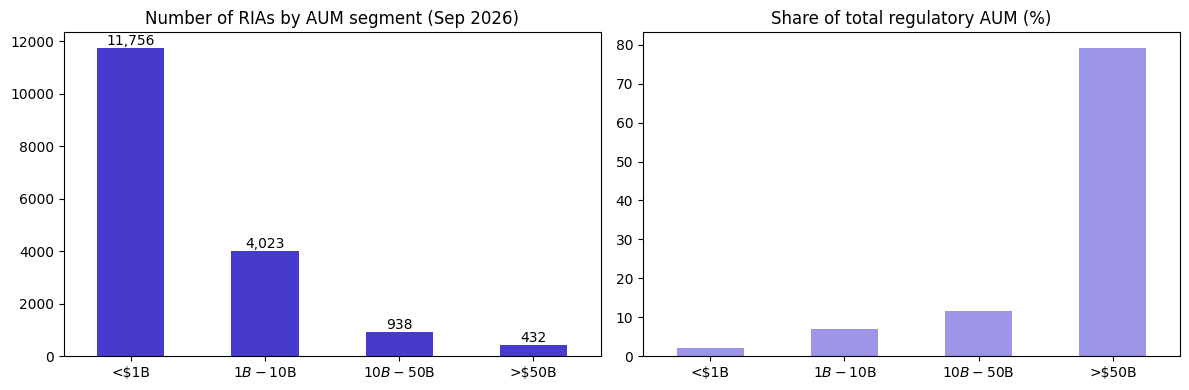

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
seg.RIAs.plot.bar(ax=ax[0], color="#473BCE"); ax[0].set_title("Number of RIAs by AUM segment (Sep 2026)")
for i, v in enumerate(seg.RIAs): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
(seg.share_of_aum * 100).plot.bar(ax=ax[1], color="#9C94E6"); ax[1].set_title("Share of total regulatory AUM (%)")
for a in ax: a.set_xlabel(""); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Commentary.** The market is a long tail with a heavy head. Two-thirds of firms are under $1B, but the 432 firms above $50B hold 79% of assets (mostly asset managers: Vanguard, Fidelity, BlackRock). For Nevis the relevant count is **advisor-led wealth managers**: about 1,300 firms above $1B, of which 156 are Enterprise-scale ($10B+). That's a short enough list for named-account selling, with a long tail of about 5,600 smaller firms better suited to a product-led motion.

## 6. Method for growth and staffing questions
* **Growth = CAGR** between September snapshots: 1-year = 2025→2026, 3-year = 2023→2026, 5-year = 2021→2026. Firms must exist at both ends.
* **Minimum starting AUM scaled to the segment** (20% of the segment floor, never below $100M): $100M for <$1B, $200M for $1B-$10B, $2B for $10B-$50B, $10B for >$50B. This stops a $100M → $15B re-registration from "winning" the larger segments.
* **Headcount reclassification flag:** advisor count falling more than 60% in a single year (e.g. Vanguard 301 → 19) is a change in how Item 5.B(1) was answered, not attrition. Excluded from the ranked lists.
* **Inorganic / step-change flag:** any single year where AUM grew more than 2.5x or advisor headcount more than doubled, or a reported succession (Item 4.A). These are usually acquisitions, re-registrations or roll-ups into a new entity. They are **ranked separately** so the main lists show sustained growth.
* **Excess growth** = firm CAGR minus its segment's median CAGR, which strips out the market tailwind every firm shared.
* **Segment = September 2026 AUM.** Firms are compared with the peers they are today.
* **Advisor-led wealth manager view (Nevis ICP):** at least 50% of AUM from individuals or HNW clients, offers financial planning (5.G(1)), has registered IARs, and no more than 500 clients per advisor. The last test removes robo-advisors, TAMPs and model-delivery platforms, which also serve "individuals" but aren't advisor-led. The unfiltered lists are dominated by asset managers and fund advisers.

In [10]:
MIN_START = {"<$1B": 100e6, "$1B-$10B": 200e6, "$10B-$50B": 2e9, ">$50B": 10e9}
p = firm_year.pivot_table(index="crd", columns="year", values=["aum", "advisors"])
succ = panel.pivot_table(index="crd", columns="year", values="succession", aggfunc="max")

def window(h, end=2026):
    s0 = end - h
    w = pd.DataFrame({"aum_start": p["aum"][s0], "aum_end": p["aum"][end],
                      "adv_start": p["advisors"][s0], "adv_end": p["advisors"][end]}).dropna(subset=["aum_start", "aum_end"])
    w["segment"] = seg_map.reindex(w.index).values
    w = w[(w.aum_start >= w.segment.astype(str).map(MIN_START)) & (w.aum_end > 0)]
    w["aum_cagr"] = (w.aum_end / w.aum_start) ** (1 / h) - 1
    ok = (w.adv_start >= 3) & (w.adv_end >= 1)
    w["advisor_cagr"] = np.where(ok, (w.adv_end / w.adv_start) ** (1 / h) - 1, np.nan)
    w["staffing_gap"] = w.aum_cagr - w.advisor_cagr
    w["excess_growth"] = w.aum_cagr - w.groupby("segment", observed=False).aum_cagr.transform("median")
    yrs = list(range(s0, end + 1))
    a, v = p["aum"].reindex(w.index)[yrs], p["advisors"].reindex(w.index)[yrs]
    aum_jump = (a / a.shift(axis=1)).iloc[:, 1:].max(axis=1)
    adv_jump = (v / v.shift(axis=1).where(v.shift(axis=1) >= 3)).iloc[:, 1:].max(axis=1)
    succ_w = succ.reindex(w.index)[[y for y in yrs[1:] if y in succ.columns]].fillna(False).astype(bool).any(axis=1)
    adv_drop = (v / v.shift(axis=1).where(v.shift(axis=1) >= 3)).iloc[:, 1:].min(axis=1)
    w["inorganic_flag"] = (aum_jump > 2.5).values | (adv_jump > 2).fillna(False).values | succ_w.values
    w["headcount_reclass"] = (adv_drop < 0.4).fillna(False).values   # >60% advisor drop in a year = reporting change, not attrition
    w = w.join(ident.set_index("crd")[["firm_name", "website", "website_confidence", "city", "state", "country"]])
    w = w.join(latest.set_index("crd")[["wealth_manager", "aum_per_advisor", "clients_per_advisor"]])
    w["wealth_manager"] = w.wealth_manager.fillna(False).astype(bool)
    w["horizon"] = f"{h}y"
    return w.reset_index()

win = {h: window(h) for h in (1, 3, 5)}
pd.DataFrame({f"{h}y": {"firms in window": len(w), "flagged inorganic": int(w.inorganic_flag.sum()),
                        "median AUM CAGR %": 100 * w.aum_cagr.median(), "median advisor CAGR %": 100 * w.advisor_cagr.median()}
              for h, w in win.items()}).T

,firms in window,flagged inorganic,median AUM CAGR %,median advisor CAGR %
1y,"13,921.00",280.00,14.38,0.00
3y,"11,742.00",471.00,13.23,0.00
5y,"10,034.00",606.00,9.19,1.30


In [11]:
def fmt(df):
    out = df.copy()
    for c in ["aum_start", "aum_end", "aum"]:
        if c in out: out[c] = (out[c] / 1e9).round(2)
    if "aum_per_advisor" in out: out["aum_per_advisor"] = (out["aum_per_advisor"] / 1e6).round(0)
    for c in ["aum_cagr", "advisor_cagr", "staffing_gap", "excess_growth", "retail_aum_share"]:
        if c in out: out[c] = (out[c] * 100).round(1)
    return out.rename(columns={"aum_start": "AUM start $B", "aum_end": "AUM end $B", "aum": "AUM $B", "aum_cagr": "AUM CAGR %",
                               "advisor_cagr": "Advisor CAGR %", "staffing_gap": "Gap (pp)", "excess_growth": "vs seg. median (pp)",
                               "aum_per_advisor": "AUM/advisor $M", "retail_aum_share": "Retail AUM %"})

def top_by_segment(df, metric, n=10, wealth_only=False, cols=None, organic=False):
    d = df[df.wealth_manager.fillna(False).astype(bool)] if wealth_only else df
    if organic: d = d[~d.inorganic_flag & ~d.headcount_reclass]
    d = d.dropna(subset=[metric]).sort_values(metric, ascending=False)
    return d.groupby("segment", observed=True, group_keys=False).head(n)[["segment"] + cols]

## 7. Q1: Who are the fastest-growing firms?

In [12]:
G = ["firm_name", "state", "aum_start", "aum_end", "aum_cagr", "excess_growth", "wealth_manager"]
fast = {h: top_by_segment(win[h], "aum_cagr", cols=G, organic=True) for h in (1, 3, 5)}
fast_wm = {h: top_by_segment(win[h], "aum_cagr", wealth_only=True, cols=G, organic=True) for h in (1, 3, 5)}
print("Fastest growing, 3-year AUM CAGR (all RIAs, sustained growth)"); fmt(fast[3])

Fastest growing, 3-year AUM CAGR (all RIAs, sustained growth)


,segment,firm_name,state,AUM start $B,AUM end $B,AUM CAGR %,vs seg. median (pp),wealth_manager
11136,$1B-$10B,"DIVISADERO STREET CAPITAL MANAGEMENT, LP",FL,0.28,2.61,110.90,96.70,False
4353,$1B-$10B,"CLEAR HAVEN CAPITAL MANAGEMENT, LLC",NY,0.25,2.18,107.20,92.90,False
9931,$1B-$10B,"PRYSM CAPITAL, L.P.",NJ,0.83,6.86,102.40,88.10,False
9174,$1B-$10B,EMPROS CAPITAL LLC,CA,0.32,2.34,94.60,80.30,False
4362,$10B-$50B,"GOTHAM ASSET MANAGEMENT, LLC",NY,4.20,30.03,92.60,80.50,False
10903,<$1B,EMBASSY ASSET MANAGEMENT LP,NJ,0.11,0.77,92.10,79.20,False
9659,$1B-$10B,"59 NORTH CAPITAL MANAGEMENT, LP",TX,1.08,7.50,90.90,76.60,False
11279,$1B-$10B,"SPEARHEAD ADMINISTRATIVE SERVICES, LLC",DE,0.57,3.83,89.00,74.80,False
7849,<$1B,"BG INVESTMENT SERVICES, LLC",NaN,0.13,0.87,87.30,74.50,False
9734,$1B-$10B,NORTH OF SOUTH CAPITAL LLP,NaN,1.03,6.70,86.70,72.50,False


In [13]:
print("Fastest growing, 1-year AUM growth (all RIAs, sustained growth)"); fmt(fast[1])

Fastest growing, 1-year AUM growth (all RIAs, sustained growth)


,segment,firm_name,state,AUM start $B,AUM end $B,AUM CAGR %,vs seg. median (pp),wealth_manager
5009,<$1B,"KABOUTER MANAGEMENT, LLC",IL,0.40,0.99,148.80,134.70,False
8858,$1B-$10B,FORGE GLOBAL ADVISORS LLC,CA,0.99,2.46,148.80,133.80,False
12239,$1B-$10B,"DIVISADERO STREET CAPITAL MANAGEMENT, LP",FL,1.05,2.61,148.40,133.40,False
4650,$10B-$50B,"GOTHAM ASSET MANAGEMENT, LLC",NY,12.13,30.03,147.70,133.60,False
13439,<$1B,"BAYPOINTE PARTNERS, LLC",CT,0.11,0.27,147.40,133.30,False
12291,$1B-$10B,QUANTIX COMMODITIES LP,CT,0.79,1.95,146.60,131.70,False
12581,$1B-$10B,INNOVATION X ADVISORS,MD,1.83,4.52,146.40,131.40,False
10651,<$1B,"HUDSON CAPITAL ADVISORY, INC.",NY,0.13,0.33,146.30,132.30,False
6265,$1B-$10B,"RIZVI TRAVERSE MANAGEMENT, LLC",FL,0.52,1.29,146.00,131.10,False
8467,$1B-$10B,MVP MANAGER LLC,NY,1.14,2.81,145.50,130.50,False


In [14]:
print("Fastest growing, 5-year AUM CAGR (all RIAs, sustained growth)"); fmt(fast[5])

Fastest growing, 5-year AUM CAGR (all RIAs, sustained growth)


,segment,firm_name,state,AUM start $B,AUM end $B,AUM CAGR %,vs seg. median (pp),wealth_manager
9060,$1B-$10B,"59 NORTH CAPITAL MANAGEMENT, LP",TX,0.43,7.50,77.40,66.20,False
9143,$1B-$10B,"HILDRED CAPITAL MANAGEMENT, LLC",NY,0.23,3.92,75.60,64.50,False
9643,$1B-$10B,TWO SEAS CAPITAL LP,NY,0.21,2.82,68.60,57.40,False
8253,>$50B,INNOCAP GLOBAL INVESTMENT MANAGEMENT (IRELAND)...,NaN,10.99,141.06,66.60,56.20,False
8568,$10B-$50B,SONA ASSET MANAGEMENT (US) LLC,NY,2.84,33.49,63.80,54.40,False
9114,$1B-$10B,NORTH OF SOUTH CAPITAL LLP,NaN,0.59,6.70,62.80,51.70,False
8295,$1B-$10B,ARKADIOS WEALTH ADVISORS,GA,0.81,8.79,61.00,49.80,True
1985,$1B-$10B,CONTEXT CAPITAL MANAGEMENT LLC,CT,0.78,8.01,59.40,48.30,False
9033,$1B-$10B,"THIRD LAKE PARTNERS, LLC",FL,0.58,5.97,59.30,48.10,False
7514,>$50B,SCHONFELD STRATEGIC ADVISORS LLC,NY,22.03,225.25,59.20,48.80,False


In [15]:
print("Fastest-growing ADVISOR-LED WEALTH MANAGERS, 3-year CAGR"); fmt(fast_wm[3])

Fastest-growing ADVISOR-LED WEALTH MANAGERS, 3-year CAGR


,segment,firm_name,state,AUM start $B,AUM end $B,AUM CAGR %,vs seg. median (pp),wealth_manager
11298,$1B-$10B,49 FINANCIAL,TX,0.23,1.40,82.60,68.30,True
2010,$10B-$50B,"WAVERLY ADVISORS, LLC",AL,5.78,29.87,72.90,60.80,True
8769,$1B-$10B,ARKADIOS WEALTH ADVISORS,GA,1.76,8.79,71.00,56.70,True
8500,$1B-$10B,"WISS PRIVATE CLIENT ADVISORS, LLC",NJ,0.25,1.22,70.10,55.90,True
1830,<$1B,"MWA FINANCIAL SERVICES, INC.",IL,0.14,0.64,67.70,54.90,True
8229,$1B-$10B,"CLARK ASSET MANAGEMENT, LLC",NaN,0.28,1.32,67.50,53.20,True
7934,$1B-$10B,AERODIGM WEALTH LLC,OR,0.32,1.46,66.40,52.10,True
9158,<$1B,MAIA WEALTH,CO,0.21,0.97,65.80,52.90,True
7127,$10B-$50B,APELLA WEALTH,CT,2.48,11.07,64.70,52.60,True
4570,>$50B,PATHSTONE,NJ,24.84,110.30,64.40,50.90,True


In [16]:
print("Inorganic / step-change movers, 3-year (acquisitions, re-registrations, roll-ups): advisor-led wealth managers")
fmt(top_by_segment(win[3][win[3].inorganic_flag], "aum_cagr", n=5, wealth_only=True, cols=G + ["adv_start", "adv_end"]))

Inorganic / step-change movers, 3-year (acquisitions, re-registrations, roll-ups): advisor-led wealth managers


,segment,firm_name,state,AUM start $B,AUM end $B,AUM CAGR %,vs seg. median (pp),wealth_manager,adv_start,adv_end
11225,$1B-$10B,"VESTGEN ADVISORS, LLC",IL,0.53,6.67,132.80,118.50,True,7.00,58.00
3215,$1B-$10B,PROSPERITY - AN EISNERAMPER COMPANY,MD,0.41,5.04,131.40,117.10,True,8.00,60.00
7196,$1B-$10B,"COMPOUND PLANNING, INC.",NY,0.43,4.85,124.30,110.00,True,18.00,76.00
10843,$1B-$10B,"IMPACT PARTNERSHIP WEALTH, LLC",GA,0.29,2.96,116.50,102.30,True,33.00,89.00
5588,>$50B,"FOCUS PARTNERS WEALTH, LLC",MO,18.83,181.86,113.00,99.50,True,215.00,"1,025.00"
11387,<$1B,ENCOMPASS MORE ASSET MANAGEMENT LLC,CA,0.11,0.98,105.60,92.70,True,32.00,85.00
11553,<$1B,CANOPY PARTNERS,OH,0.10,0.87,102.40,89.60,True,1.00,3.00
7683,>$50B,"OSAIC WEALTH, INC.",AZ,29.54,234.86,99.60,86.20,True,"2,075.00","7,143.00"
8237,$1B-$10B,ONEASCENT FINANCIAL SERVICES LLC,AL,0.46,3.54,97.90,83.60,True,25.00,74.00
310,>$50B,CETERA INVESTMENT ADVISERS LLC,IL,33.36,256.81,97.50,84.00,True,"2,788.00","9,049.00"


**Commentary.**
* **The unfiltered winners are mostly alternatives and fund managers** (hedge, credit, ETF sponsors), whose AUM moves with fund launches and inflows. That's the literal answer, but not Nevis's market.
* **Among advisor-led wealth managers**, the standouts are multi-billion-dollar firms compounding at 60-70%+ a year: Waverly, Arkadios, Apella, Pathstone, Merit. Excess growth versus the segment median of over 50pp shows this isn't just the market.
* **The inorganic list is a sales signal in its own right.** Focus Partners (215 → 1,025 advisors), Osaic and Cetera (thousands of advisors folded into one registrant) are integrating acquired teams, each with its own workflows and tech stack. Standardising meeting prep, notes and CRM hygiene across a newly merged advisor base is a strong Nevis entry point.
* The 1-year view is noisier (fund launches, re-registrations) and is best read alongside the 3- and 5-year views.

## 8. Q2: Which firms are capacity-strained (highest AUM per advisor)?
Measured on September 2026, firms with at least 3 advisors (so single-person shops don't dominate). Shown for all RIAs (the literal answer) and for wealth managers, where **clients per advisor** is shown too. For a wealth manager, clients per advisor is the truer measure of strain, because advisor time scales with relationships, not dollars.

In [17]:
cap = latest[(latest.advisors >= 3) & (latest.aum > 0)].copy()
cap["wealth_manager"] = cap.wealth_manager.fillna(False).astype(bool)
C = ["firm_name", "state", "aum", "advisors", "iars", "aum_per_advisor", "clients_per_advisor", "retail_aum_share"]
cap_all = top_by_segment(cap, "aum_per_advisor", cols=C)
cap_wm = top_by_segment(cap, "aum_per_advisor", wealth_only=True, cols=C)
print("Highest AUM per advisor (all RIAs)"); fmt(cap_all)

Highest AUM per advisor (all RIAs)


,segment,firm_name,state,AUM $B,advisors,iars,AUM/advisor $M,clients_per_advisor,Retail AUM %
93157,>$50B,VANGUARD GROUP INC,PA,"11,092.67",19.00,0.00,"583,824.00",12.00,0.00
79644,>$50B,"ALLSPRING FUNDS MANAGEMENT, LLC",NC,324.65,3.00,0.00,"108,218.00","3,372.67",2.50
93182,>$50B,TAULA CAPITAL MANAGEMENT (DIFC) LTD,NaN,210.92,4.00,0.00,"52,730.00",1.00,0.00
80160,>$50B,"GEODE CAPITAL MANAGEMENT, LLC",MA,"1,736.52",37.00,0.00,"46,933.00",4.80,0.00
82153,>$50B,MANAGED ACCOUNT ADVISORS LLC,NJ,994.99,25.00,25.00,"39,800.00","57,850.32",90.30
94088,>$50B,ICICI ASSET MANAGEMENT,NaN,117.06,3.00,0.00,"39,020.00","9,432.00",2.10
94535,>$50B,"VANGUARD CAPITAL MANAGEMENT, LLC",PA,"8,436.18",235.00,0.00,"35,899.00",0.54,0.00
78305,>$50B,BLACKROCK FUND ADVISORS,CA,"4,282.22",122.00,2.00,"35,100.00",4.35,0.00
94486,>$50B,TAULA CAPITAL MANAGEMENT (JERSEY) LP,NaN,210.93,7.00,0.00,"30,133.00",0.86,0.00
93212,>$50B,"BNY MELLON INVESTMENT ADVISER, INC.",NY,419.46,14.00,0.00,"29,962.00",6.50,0.00


In [18]:
print("Highest AUM per advisor (wealth managers)"); fmt(cap_wm)

Highest AUM per advisor (wealth managers)


,segment,firm_name,state,AUM $B,advisors,iars,AUM/advisor $M,clients_per_advisor,Retail AUM %
86366,$1B-$10B,"PROWELL FINANCIAL MANAGEMENT, LLC",PA,6.86,3.00,3.00,"2,288.00",24.67,97.30
81543,$1B-$10B,"WHARTON BUSINESS GROUP, LLC",PA,4.57,3.00,3.00,"1,522.00",41.33,81.70
81017,$1B-$10B,YALE CAPITAL CORP.,FL,5.62,4.00,5.00,"1,405.00",29.50,100.00
82185,$10B-$50B,"CIRCLE WEALTH MANAGEMENT, LLC",NJ,14.07,11.00,10.00,"1,279.00",34.77,92.80
80775,$1B-$10B,"FRANK, RIMERMAN ADVISORS LLC",CA,3.40,3.00,2.00,"1,133.00",36.17,99.80
78356,$1B-$10B,ACCREDITED INVESTORS WEALTH MANAGEMENT,MN,4.41,4.00,4.00,"1,103.00",236.75,99.50
79113,$1B-$10B,"MILLER INVESTMENT MANAGEMENT, LP",PA,7.10,7.00,6.00,"1,015.00",26.50,88.80
78796,$10B-$50B,"LORING, WOLCOTT & COOLIDGE FIDUCIARY ADVISORS,...",MA,12.84,13.00,10.00,987.00,253.27,94.50
92453,$1B-$10B,L 1 GLOBAL WEALTH LLC,FL,2.81,3.00,4.00,937.00,5.67,100.00
85069,$1B-$10B,"COLONY FAMILY OFFICES, LLC",NC,3.36,4.00,7.00,841.00,164.00,95.90


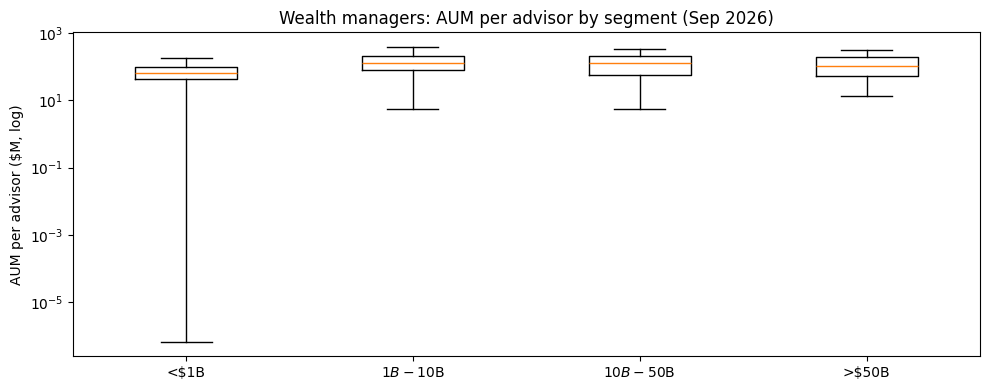

,median AUM/advisor $M,clients_per_advisor
segment,,
<$1B,64.61,62.00
$1B-$10B,130.12,66.97
$10B-$50B,125.74,61.59
>$50B,107.16,80.57


In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
data = [cap[(cap.segment == s) & cap.wealth_manager].aum_per_advisor.dropna() / 1e6 for s in LABELS]
ax.boxplot(data, labels=LABELS, showfliers=False); ax.set_yscale("log")
ax.set_ylabel("AUM per advisor ($M, log)"); ax.set_title("Wealth managers: AUM per advisor by segment (Sep 2026)")
plt.tight_layout(); plt.show()
cap[cap.wealth_manager].groupby("segment", observed=True)[["aum_per_advisor", "clients_per_advisor"]].median().assign(aum_per_advisor=lambda x: x.aum_per_advisor / 1e6).rename(columns={"aum_per_advisor": "median AUM/advisor $M"})

**Commentary.**
* **All-RIA rankings are dominated by fund complexes** (Vanguard at $584B per "advisor"), because a handful of portfolio managers run pooled vehicles. This is why the ICP filter matters.
* **For advisor-led wealth managers, capacity is better read as clients per advisor.** The median $1B+ firm has 60-80 clients per advisor; firms above 150-200 are where meeting volume, follow-ups and compliance documentation pile up.
* **High AUM per advisor with few clients** (Circle Wealth, BBR Partners, Vernal Point) usually means ultra-HNW or family-office models. They have fewer, deeper relationships, and the pain is preparation and reporting quality more than volume. A different Nevis pitch from high-client-load firms.

## 9. Q3: Which RIAs appear under-staffed?
**Staffing gap = AUM CAGR minus advisor-headcount CAGR** over 1, 3 and 5 years. A positive gap means each advisor is carrying more AUM every year. Requires at least 3 advisors at the start of the window (so 1→2 hires don't create noise) and the segment minimum starting AUM, and excludes inorganic step-changes.

In [20]:
S = ["firm_name", "state", "aum_end", "aum_cagr", "advisor_cagr", "staffing_gap", "adv_start", "adv_end", "wealth_manager"]
gap = {h: top_by_segment(win[h], "staffing_gap", cols=S, organic=True) for h in (1, 3, 5)}
gap_wm = {h: top_by_segment(win[h], "staffing_gap", wealth_only=True, cols=S, organic=True) for h in (1, 3, 5)}
print("Under-staffed, 3-year (all RIAs)"); fmt(gap[3])

Under-staffed, 3-year (all RIAs)


,segment,firm_name,state,AUM end $B,AUM CAGR %,Advisor CAGR %,Gap (pp),adv_start,adv_end,wealth_manager
9931,$1B-$10B,"PRYSM CAPITAL, L.P.",NJ,6.86,102.40,4.00,98.40,8.00,9.00,False
4353,$1B-$10B,"CLEAR HAVEN CAPITAL MANAGEMENT, LLC",NY,2.18,107.20,14.50,92.70,4.00,6.00,False
9174,$1B-$10B,EMPROS CAPITAL LLC,CA,2.34,94.60,4.00,90.60,8.00,9.00,False
11059,$1B-$10B,TANGENCY CAPITAL INVESTMENT ADVISORY LTD.,NaN,3.45,69.40,-20.60,90.00,4.00,2.00,False
4362,$10B-$50B,"GOTHAM ASSET MANAGEMENT, LLC",NY,30.03,92.60,3.20,89.40,20.00,22.00,False
11279,$1B-$10B,"SPEARHEAD ADMINISTRATIVE SERVICES, LLC",DE,3.83,89.00,0.00,89.00,3.00,3.00,False
10375,$1B-$10B,"MWP ADVISORY, LLC",NY,1.65,79.40,0.00,79.40,7.00,7.00,False
9734,$1B-$10B,NORTH OF SOUTH CAPITAL LLP,NaN,6.70,86.70,10.10,76.70,6.00,8.00,False
10923,$1B-$10B,ARCHITECT CAPITAL CORP.,CA,1.23,82.70,6.30,76.50,5.00,6.00,False
10902,<$1B,HURRICANE CAPITAL ADVISORS LLC,NY,0.60,49.30,-26.30,75.60,10.00,4.00,False


In [21]:
print("Under-staffed, 1-year (all RIAs)"); fmt(gap[1])

Under-staffed, 1-year (all RIAs)


,segment,firm_name,state,AUM end $B,AUM CAGR %,Advisor CAGR %,Gap (pp),adv_start,adv_end,wealth_manager
13009,$1B-$10B,AC WEALTH PARTNERS,PA,1.07,129.30,-40.00,169.30,5.00,3.00,False
6939,<$1B,TENCAP WEALTH COACHING,UT,0.29,143.20,-22.20,165.40,9.00,7.00,True
5009,<$1B,"KABOUTER MANAGEMENT, LLC",IL,0.99,148.80,-12.50,161.30,8.00,7.00,False
12291,$1B-$10B,QUANTIX COMMODITIES LP,CT,1.95,146.60,-8.30,155.00,12.00,11.00,False
3783,<$1B,CRESCAT PORTFOLIO MANAGEMENT LLC,CO,0.54,139.60,-14.30,153.80,7.00,6.00,False
13450,<$1B,"OUTRUNNER CAPITAL, LLC",TX,0.50,113.70,-40.00,153.70,5.00,3.00,True
13034,$1B-$10B,CONSTELLATION WEALTH CAPITAL,IL,2.52,99.30,-52.60,151.90,19.00,9.00,False
8938,$1B-$10B,"LESTE CAPITAL PARTNERS (FLORIDA), LLC",FL,1.61,114.40,-34.80,149.10,23.00,15.00,False
12581,$1B-$10B,INNOVATION X ADVISORS,MD,4.52,146.40,0.00,146.40,3.00,3.00,False
10651,<$1B,"HUDSON CAPITAL ADVISORY, INC.",NY,0.33,146.30,0.00,146.30,3.00,3.00,False


In [22]:
print("Under-staffed, 5-year (all RIAs)"); fmt(gap[5])

Under-staffed, 5-year (all RIAs)


,segment,firm_name,state,AUM end $B,AUM CAGR %,Advisor CAGR %,Gap (pp),adv_start,adv_end,wealth_manager
6929,>$50B,SQUAREPOINT OPS LLC,NY,226.98,44.30,-27.40,71.80,303.00,61.00,False
9060,$1B-$10B,"59 NORTH CAPITAL MANAGEMENT, LP",TX,7.50,77.40,10.80,66.60,3.00,5.00,False
8763,$1B-$10B,"QUID CAPITAL GROUP HOLDINGS, LLC",CA,7.76,57.90,-5.60,63.50,8.00,6.00,False
8253,>$50B,INNOCAP GLOBAL INVESTMENT MANAGEMENT (IRELAND)...,NaN,141.06,66.60,3.70,62.90,5.00,6.00,False
9643,$1B-$10B,TWO SEAS CAPITAL LP,NY,2.82,68.60,7.00,61.60,5.00,7.00,False
8273,<$1B,"HILLCREST CREDIT AND INCOME FUND II MANAGER, LLC",NY,0.49,34.80,-24.20,59.00,4.00,1.00,False
8003,$1B-$10B,FACET,FL,7.60,56.60,0.00,56.60,77.00,77.00,True
1985,$1B-$10B,CONTEXT CAPITAL MANAGEMENT LLC,CT,8.01,59.40,5.90,53.50,6.00,8.00,False
8760,$1B-$10B,NORTH HUDSON RESOURCE PARTNERS LP,TX,2.58,56.50,3.10,53.40,6.00,7.00,False
6733,$1B-$10B,BLUEPRINT INVESTMENT PARTNERS LLC,NC,1.78,39.50,-12.90,52.40,6.00,3.00,False


In [23]:
print("Under-staffed WEALTH MANAGERS, 3-year"); fmt(gap_wm[3])

Under-staffed WEALTH MANAGERS, 3-year


,segment,firm_name,state,AUM end $B,AUM CAGR %,Advisor CAGR %,Gap (pp),adv_start,adv_end,wealth_manager
8500,$1B-$10B,"WISS PRIVATE CLIENT ADVISORS, LLC",NJ,1.22,70.10,4.00,66.10,8.00,9.00,True
8434,$1B-$10B,FACET,FL,7.60,54.10,-10.90,65.00,109.00,77.00,True
8769,$1B-$10B,ARKADIOS WEALTH ADVISORS,GA,8.79,71.00,9.50,61.50,115.00,151.00,True
8957,<$1B,"FORTRESS PRIVATE LEDGER, LLC",NC,0.58,60.30,0.00,60.30,13.00,13.00,True
8760,$1B-$10B,"KINGSWOOD WEALTH ADVISORS, LLC",CA,3.80,57.70,-0.90,58.50,78.00,76.00,True
9836,<$1B,CONVERGENCE FINANCIAL,MO,0.90,44.70,-13.40,58.10,20.00,13.00,True
9032,<$1B,"REDWOOD FINANCIAL PLANNING, LLC",NJ,0.39,56.60,0.00,56.60,3.00,3.00,True
8764,<$1B,"BEACON GLOBAL ADVISOR NETWORK, LLC",GA,0.75,63.90,10.70,53.20,45.00,61.00,True
5056,<$1B,ALPHA SOLUTIONS INVESTMENT ADVISORS,CA,0.47,61.70,10.10,51.70,3.00,4.00,True
10608,<$1B,"RETIREMENT PLANNING SOLUTIONS, LLC",KY,0.47,33.80,-17.80,51.60,9.00,5.00,True


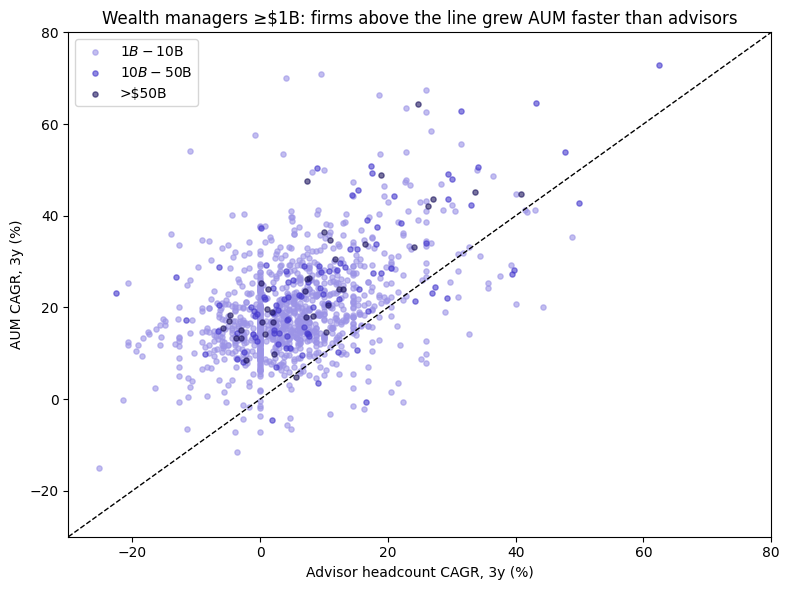

$1B+ advisor-led wealth managers: 1,145 | grew AUM faster than advisors: 92% | median AUM CAGR 18.1% vs advisor CAGR 4.6%


In [24]:
w3 = win[3][win[3].wealth_manager & ~win[3].inorganic_flag & ~win[3].headcount_reclass & win[3].advisor_cagr.notna() & (win[3].aum_end >= 1e9)]
fig, ax = plt.subplots(figsize=(8, 6))
for s, c in zip(LABELS[1:], ["#9C94E6", "#473BCE", "#1E1660"]):
    d = w3[w3.segment == s]; ax.scatter(d.advisor_cagr * 100, d.aum_cagr * 100, s=14, alpha=.6, label=s, color=c)
lim = [-30, 80]; ax.plot(lim, lim, "k--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Advisor headcount CAGR, 3y (%)"); ax.set_ylabel("AUM CAGR, 3y (%)")
ax.set_title("Wealth managers ≥$1B: firms above the line grew AUM faster than advisors"); ax.legend()
plt.tight_layout(); plt.show()
print(f"$1B+ advisor-led wealth managers: {len(w3):,} | grew AUM faster than advisors: {(w3.staffing_gap > 0).mean():.0%}"
      f" | median AUM CAGR {w3.aum_cagr.median():.1%} vs advisor CAGR {w3.advisor_cagr.median():.1%}")

**Commentary.**
* **Under-staffing is the norm, not the exception:** 92% of $1B+ advisor-led firms sit above the diagonal. The industry's well-known advisor shortage shows up directly in the ADV data.
* **Firms growing AUM 50-70% a year with flat or falling advisor headcount** (Arkadios, Kingswood, Facet, Wiss) are the clearest cases of "growth outrunning capacity". They have budget and an urgent need for leverage per advisor.
* Unfiltered lists again surface fund managers and some reclassifications (Apollo Credit's advisor count fell from 2,540 to 912 as reporting changed), which the wealth-manager view and reclassification flag remove.

## 10. So what for Nevis: a prioritised target list
The three signals combined into one score for **US advisor-led wealth managers with 5+ advisors**, ranked within each segment by percentile (equal weights):
1. **3-year AUM CAGR**: momentum and budget.
2. **AUM per advisor (Sep 2026)**: current capacity strain.
3. **3-year staffing gap**: strain that is getting worse.

In [25]:
t = win[3][win[3].wealth_manager & win[3].staffing_gap.notna() & win[3].aum_per_advisor.notna()
           & (win[3].adv_end >= 5) & (win[3].country == "United States")].copy()
for m in ["aum_cagr", "aum_per_advisor", "staffing_gap"]:
    t[f"{m}_pctl"] = t.groupby("segment", observed=True)[m].rank(pct=True)
t["nevis_score"] = t[["aum_cagr_pctl", "aum_per_advisor_pctl", "staffing_gap_pctl"]].mean(axis=1) * 100
T = ["firm_name", "website", "website_confidence", "city", "state", "aum_end", "aum_cagr", "aum_per_advisor", "clients_per_advisor", "staffing_gap", "adv_end", "inorganic_flag", "nevis_score"]
targets = (t.sort_values("nevis_score", ascending=False).groupby("segment", observed=True, group_keys=False).head(10)
           .sort_values(["segment", "nevis_score"], ascending=[False, False])[["segment"] + T])
fmt(targets).rename(columns={"adv_end": "advisors"})

,segment,firm_name,website,website_confidence,city,state,AUM end $B,AUM CAGR %,AUM/advisor $M,clients_per_advisor,Gap (pp),advisors,inorganic_flag,nevis_score
8725,>$50B,"CRESSET ASSET MANAGEMENT, LLC",www.cressetpartners.com,name match,Chicago,IL,78.94,47.50,422.00,26.26,40.10,187.00,False,93.65
4570,>$50B,PATHSTONE,www.pathstone.com,verified,Englewood,NJ,110.30,64.40,302.00,6.15,39.60,365.00,False,92.86
5588,>$50B,"FOCUS PARTNERS WEALTH, LLC",www.focuspartners.com,verified,St. Louis,MO,181.86,113.00,177.00,60.94,44.70,"1,025.00",True,88.10
1284,>$50B,"MAI CAPITAL MANAGEMENT, LLC",www.mai.capital,name match,Cleveland,OH,52.10,48.90,227.00,70.75,30.10,230.00,False,87.30
721,>$50B,SAVANT WEALTH MANAGEMENT,www.savantwealth.com,name match,Rockford,IL,55.61,43.80,234.00,100.98,16.70,238.00,False,72.22
4906,>$50B,"CWM, LLC",www.carsonwealth.com,verified,Omaha,NE,50.58,36.40,107.00,111.59,26.30,472.00,False,71.43
7683,>$50B,"OSAIC WEALTH, INC.",www.osaic.com,verified,Scottsdale,AZ,234.86,99.60,33.00,80.57,48.60,"7,143.00",True,70.63
9795,>$50B,"IEQ CAPITAL, LLC",www.ieqcapital.com,name match,Foster City,CA,56.77,45.20,294.00,11.96,11.70,193.00,False,70.63
744,>$50B,FISHER INVESTMENTS,www.fisherinvestments.com,verified,Plano,TX,386.67,26.20,198.00,102.63,18.80,"1,948.00",False,69.05
310,>$50B,CETERA INVESTMENT ADVISERS LLC,www.cetera.com,verified,Schaumburg,IL,256.81,97.50,28.00,89.95,49.40,"9,049.00",True,68.25


**How to use this list.** The score is a prioritisation aid, not a verdict:
* **$50B+ (Enterprise):** Cresset, Pathstone, Focus Partners, MAI, Savant, Carson, IEQ and Fisher combine scale, strong growth and rising AUM per advisor. Osaic and Cetera are a different motion: very large networks with low AUM per advisor, where the opportunity is giving thousands of independent advisors consistent tooling.
* **$10B-$50B:** Aptus, RWA, Clearstead, Merit, Apella, Apollon, NewEdge and Steward are fast-growing aggregators or multi-office firms, an ideal mid-market Enterprise wedge.
* **Next step to sharpen it:** add custodian (Schedule D 5.K(3)), tech-stack signals and recent M&A announcements, then validate the top 20 with account research before outreach.

## 11. Assumptions & limitations
* **Universe:** SEC-registered advisers only. State-registered RIAs (generally under $100M) are not in SEC data, which is immaterial for Nevis's market.
* **AUM timing:** September snapshots reflect each firm's last annual amendment, so AUM is mostly as of the prior fiscal year end.
* **Advisors** = Item 5.B(1), which includes research staff; **IARs** (5.B(3)) shown alongside as the client-facing proxy. Either can be zero for firms that sub-advise.
* **Clients** = sum of Item 5.D counts; "fewer than 5" imputed at 2.5. Funds count as one client, which is why fund managers show few clients and huge AUM per client.
* **Growth is nominal** and includes market returns; *excess growth* versus the segment median controls for this.
* **M&A:** succession (Item 4.A) is only in the snapshot from 2023; earlier deals are caught by the step-change rules (AUM >2.5x or advisors >2x in a year). Roll-ups that keep acquired firms as separate registrants won't show up as growth here.
* **Advisor-led definition** is a rules-based proxy; some hybrid firms (e.g. OCIO or family-office models) will sit on either side of the line.
* **Website:** one address per firm in the roster (see 2a). Firms listed only a social profile are labelled in `website_source`.
* **Custodians** (Schedule D 5.K(3)) are not in the roster. Adding them from the bulk ADV data would show which custodian channels reach Nevis's best targets.

## 12. How AI was used
This analysis was built with **Claude (Anthropic) working agentically**, with me directing and checking at each step:
* **Sourcing:** Claude browsed the SEC site, listed every monthly file with its size, and spotted that October and November 2025 are "no data" placeholders. That's why the series uses September.
* **Schema mapping:** compared all 448 columns across seven files (2021-22 have 262 columns), confirmed the core Item 5 fields were stable, and mapped each brief field to its Form ADV item.
* **Code:** wrote the pipeline and notebook, then ran it end to end.
* **Catching data traps:** the one-website-per-firm limitation (found via the brief's own Beacon Pointe example), base-effect and re-registration "growth", robo/TAMP platforms passing a naive wealth-manager filter, and advisor-count reclassifications. Each became an explicit, documented rule.
* **Human judgement:** snapshot timing (September for metrics, November for identity, grounded in Form ADV General Instruction 4), the ICP definition, thresholds, and the commercial framing are mine.
* **Verification:** totals reconcile with published SEC figures; zero duplicate firm-years; Beacon Pointe matches its IAPD profile ($54.9B, 440 advisors, Newport Beach); target-firm websites spot-checked by web search.

In [26]:
with pd.ExcelWriter(OUT / "nevis_ria_targets.xlsx") as xw:
    fmt(targets).to_excel(xw, sheet_name="Nevis targets", index=False)
    seg.reset_index().to_excel(xw, sheet_name="Segments", index=False)
    for h in (1, 3, 5):
        fmt(top_by_segment(win[h], "aum_cagr", n=25, cols=G, organic=True)).to_excel(xw, sheet_name=f"Fastest growth {h}y", index=False)
        fmt(top_by_segment(win[h], "staffing_gap", n=25, cols=S, organic=True)).to_excel(xw, sheet_name=f"Under-staffed {h}y", index=False)
    fmt(top_by_segment(cap, "aum_per_advisor", n=25, cols=C)).to_excel(xw, sheet_name="Capacity (all)", index=False)
    fmt(top_by_segment(cap, "aum_per_advisor", n=25, wealth_only=True, cols=C)).to_excel(xw, sheet_name="Capacity (wealth mgrs)", index=False)
    latest.drop(columns=["segment"]).assign(segment=latest.segment.astype(str)).to_excel(xw, sheet_name="Firm table (2026)", index=False)
print("Saved:", list(OUT.iterdir()))

Saved: [PosixPath('outputs/nevis_ria_targets.xlsx'), PosixPath('outputs/ria_firm_year_table.csv')]
